# Virtual control groups from NTP historical controls: a walkthrough

This notebook walks through the proof of concept step by step on the processed
data produced by `python -m vcg.cli prepare`, and then loads the full results
produced by `evaluate` and `summarise`.

Everything here is a **comparison with the real concurrent control group**. A
virtual control group (VCG) conclusion is never treated as the truth; the
concurrent control conclusion is the reference, and we ask how often the VCG
would have led a toxicologist to the same place.

Requires the processed tables (`data/processed/`) and results (`results/`) to exist.

In [1]:
%matplotlib inline
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from vcg import config as C, prepare, matching as M, stats as S, evaluation as E, methods as MM
from vcg.plots import DOMAIN_LABELS as DOM

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
data = prepare.load_processed(C.PROCESSED_DIR)
studies, meas, roster, lesions = (data[k] for k in ("studies", "measurements", "animals", "lesions"))
print({k: v.shape for k, v in data.items()})

{'studies': (1985, 12), 'measurements': (876604, 11), 'animals': (196004, 11), 'lesions': (1705213, 8), 'covariates': (130096, 4)}


## 2. What is in the data

Only F344 rats and B6C3F1/N mice from simple dose-response designs are kept:
3-month ("subchronic") studies and 2-year ("chronic") studies. The study table
carries the attributes used for matching.

In [2]:
studies.groupby(["species", "design"]).agg(studies=("study", "nunique"), labs=("laboratory", "nunique"),
                                            first_year=("year", "min"), last_year=("year", "max"))

studies  labs  first_year  last_year
species design                                          
Mouse   chronic         819    26      1971.0     2013.0
        subchronic      247    18      1981.0     2016.0
Rat     chronic         698    24      1971.0     2005.0
        subchronic      221    14      1981.0     2005.0

In [3]:
(meas.merge(studies[["study", "design"]], on="study")
     .groupby(["domain", "design"]).agg(studies=("study", "nunique"), animals=("animal", "nunique"),
                                        endpoints=("endpoint", "nunique"))
     .reset_index().pivot(index="domain", columns="design", values=["studies", "endpoints"]))

studies            endpoints           
design       chronic subchronic   chronic subchronic
domain                                              
clin_chem        NaN      123.0       NaN        9.0
hematology       NaN      190.0       NaN       13.0
inlife_bw      217.0      362.0       3.0        2.0
organ_weight     NaN      254.0       NaN        6.0
terminal_bw    467.0      368.0       1.0        1.0

In [4]:
studies["laboratory"].value_counts().head(12)

laboratory
Battelle Columbus                      337
TSI Mason Research                     325
Southern Research                      325
Battelle Northwest                     181
Litton Bionetics                       169
Hazleton                               141
Frederick Cancer Research Facility     106
BioReliance                             87
Gulf South Research Institute           66
Physiological Research Laboratories     48
IIT Research Institute                  28
<NA>                                    24
Name: count, dtype: int64

## 3. One study, one endpoint, by hand

We take a 3-month rat study with clinical chemistry, hold out its concurrent
control group, and build virtual control groups from other studies at
increasing matching strictness.

In [5]:
cands = meas[(meas["domain"] == "clin_chem") & (meas["sex"] == "Male")].merge(
    studies[["study", "species", "laboratory", "route", "vehicle", "year", "test_article"]], on="study")
cands = cands[(cands["species"] == "Rat") & (cands["laboratory"] == "Battelle Columbus") & (cands["route"] == "Gavage")]
example = cands.sort_values("year")["study"].iloc[len(cands["study"].unique()) // 2] if len(cands) else meas["study"].iloc[0]
row = studies.set_index("study").loc[example]
print(example, "|", row["test_article"], "|", row["route"], row["vehicle"], "|", row["laboratory"], int(row["year"]))
target = M.target_from_row(pd.Series({"study": example, **row.to_dict()}), "Male")
target

002-02624-0006-0000-2 | Oxymetholone | Gavage Methylcellulose, 0.5% | Battelle Columbus 1992


Target(study='002-02624-0006-0000-2', sex='Male', species='Rat', strain='F344', design='subchronic', route='Gavage', vehicle='Methylcellulose, 0.5%', laboratory='Battelle Columbus', year=1992.0, dtxsid='DTXSID5023794')

In [6]:
endpoint = "ALT"
d = meas[(meas["study"] == example) & (meas["sex"] == "Male") & (meas["endpoint"] == endpoint)]
conc = d.loc[d["is_control"], "value"].to_numpy()
doses = sorted(d.loc[~d["is_control"], "dose"].unique())
groups = [d.loc[d["dose"] == x, "value"].to_numpy() for x in doses]
print("concurrent controls:", len(conc), "animals; dose groups:", doses)
ref = S.dunnett(groups, conc)
pd.DataFrame({"dose": doses, "mean": [g.mean() for g in groups], "t": ref.statistic.round(2), "p_dunnett": ref.pvalue.round(4)})

concurrent controls: 10 animals; dose groups: [np.float64(80.0), np.float64(160.0), np.float64(315.0), np.float64(625.0), np.float64(1250.0)]


,dose,mean,t,p_dunnett
0,80.0,49.100000,-1.28,0.5795
1,160.0,44.200000,-2.94,0.0210
2,315.0,42.700000,-3.45,0.0051
3,625.0,35.777778,-5.63,0.0000
4,1250.0,38.555556,-4.72,0.0001


In [7]:
# historical control animals for this endpoint, with study metadata
hist = E._controls_with_metadata(meas[meas["endpoint"] == endpoint], studies)
hist = hist[(hist["species"] == "Rat") & (hist["sex"] == "Male") & (hist["design"] == target.design)]
pools = {lvl: M.pool_mask(hist, target, crit) for lvl, crit in C.MATCH_LEVELS.items()}
pd.DataFrame({lvl: M.describe_pool(hist, m) for lvl, m in pools.items()}).T

,n_animals,n_studies,n_labs
L0 design,739,72,8
L1 +route,240,23,4
L2 +vehicle,100,9,3
L3 +laboratory,50,5,1
L4 +period (3y),40,4,1


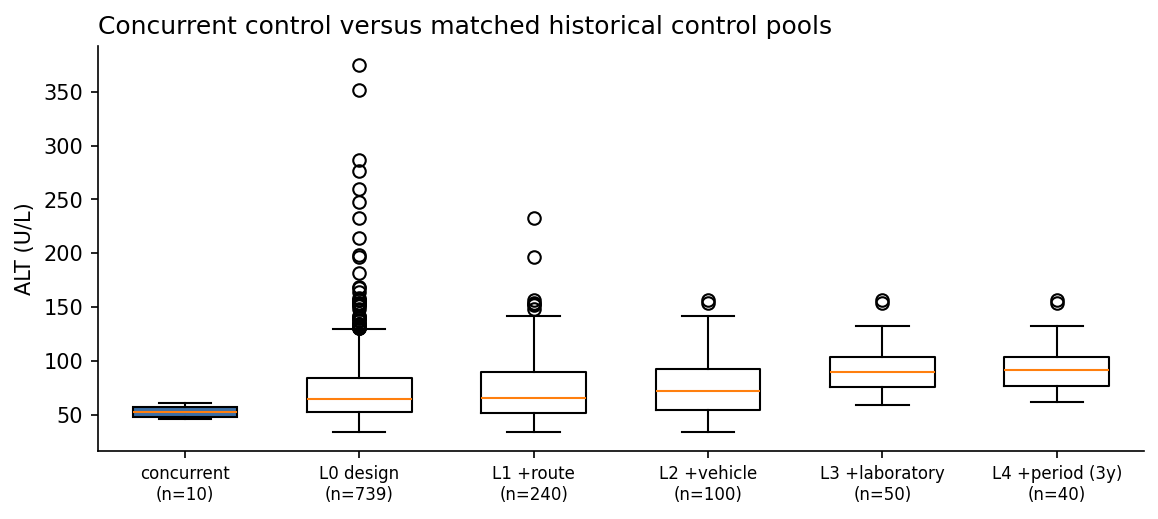

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.5))
positions, labels = [], []
ax.boxplot([conc], positions=[0], widths=0.6, patch_artist=True, boxprops=dict(facecolor="#3b6ea5"))
labels.append(f"concurrent\n(n={len(conc)})")
for i, (lvl, m) in enumerate(pools.items(), start=1):
    vals = hist.loc[m, "value"].to_numpy()
    if len(vals):
        ax.boxplot([vals], positions=[i], widths=0.6)
    labels.append(f"{lvl}\n(n={len(vals)})")
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel(f"{endpoint} ({d['unit'].iloc[0]})"); ax.set_title("Concurrent control versus matched historical control pools", loc="left")
plt.show()

Now draw virtual control groups of the same size as the concurrent group and
repeat the Dunnett test. The question is not whether the p-values are equal but
whether the *conclusion* (significant at 5% or not, per dose group) is.

In [9]:
rng = np.random.default_rng(0)
rows = []
for lvl, m in pools.items():
    pool = hist.loc[m, "value"].to_numpy()
    if len(pool) < 2 * len(conc):
        continue
    for k in range(20):
        vcg = M.draw_vcg(pool, len(conc), rng)
        res = S.dunnett(groups, vcg)
        for r, x in enumerate(doses):
            rows.append(dict(level=lvl, draw=k, dose=x, sig_conc=ref.pvalue[r] < 0.05, sig_vcg=res.pvalue[r] < 0.05))
ex = pd.DataFrame(rows)
ex["agree"] = ex["sig_conc"] == ex["sig_vcg"]
ex.groupby(["level", "dose"])[["sig_conc", "sig_vcg", "agree"]].mean().round(2)

sig_conc  sig_vcg  agree
level           dose                            
L0 design       80.0         0.0     0.90   0.10
                160.0        1.0     1.00   1.00
                315.0        1.0     1.00   1.00
                625.0        1.0     1.00   1.00
                1250.0       1.0     1.00   1.00
L1 +route       80.0         0.0     0.95   0.05
                160.0        1.0     1.00   1.00
                315.0        1.0     1.00   1.00
                625.0        1.0     1.00   1.00
                1250.0       1.0     1.00   1.00
L2 +vehicle     80.0         0.0     1.00   0.00
                160.0        1.0     1.00   1.00
                315.0        1.0     1.00   1.00
                625.0        1.0     1.00   1.00
                1250.0       1.0     1.00   1.00
L3 +laboratory  80.0         0.0     1.00   0.00
                160.0        1.0     1.00   1.00
                315.0        1.0     1.00   1.00
                625.0        1.0     1.00   1.00
                1250.0       1.0     1.00   1.00
L4 +period (3y) 80.0         0.0     1.00   0.00
                160.0        1.0     1.00   1.00
                315.0        1.0     1.00   1.00
                625.0        1.0     1.00   1.00
                1250.0       1.0     1.00   1.00

## 4. Full results

`python -m vcg.cli evaluate` repeats this for every study, sex, endpoint and dose
group, at every matching level, for full and partial VCGs, and for pools
restricted to time-gap bands. `summarise` aggregates the draws.

In [10]:
summary = json.loads((C.RESULTS_DIR / "summary.json").read_text())
{k: v for k, v in summary.items() if k not in ("figures",)}

{'headline_level': 'L3 +laboratory',
 'agreement': 0.7836,
 'false_positive': 0.1604,
 'false_negative': 0.0559,
 'fp_given_conc_nonsig': 0.2226,
 'fn_given_conc_sig': 0.2004,
 'sensitivity': 0.7996,
 'specificity': 0.7774,
 'kappa': 0.5177,
 'trivial_agreement_never_significant': 0.7208,
 'concurrent_significant_rate': 0.2792,
 'vcg_significant_rate': 0.3837,
 'n_endpoint_units': 25243,
 'n_studies': 1113,
 'n_study_sex_units': 1574,
 'n_records': 26384640,
 'n_draws': 20,
 'studies_in_processed_data': 1985,
 'by_level': {'L0 design': {'agreement': 0.7387,
   'kappa': 0.4482,
   'coverage_units': 34570},
  'L1 +route': {'agreement': 0.751, 'kappa': 0.4679, 'coverage_units': 34247},
  'L2 +vehicle': {'agreement': 0.7663,
   'kappa': 0.4922,
   'coverage_units': 31727},
  'L3 +laboratory': {'agreement': 0.7836,
   'kappa': 0.5177,
   'coverage_units': 25243},
  'L4 +period (3y)': {'agreement': 0.8021,
   'kappa': 0.554,
   'coverage_units': 20755}},
 'partial_by_level': {'L0 design': {'

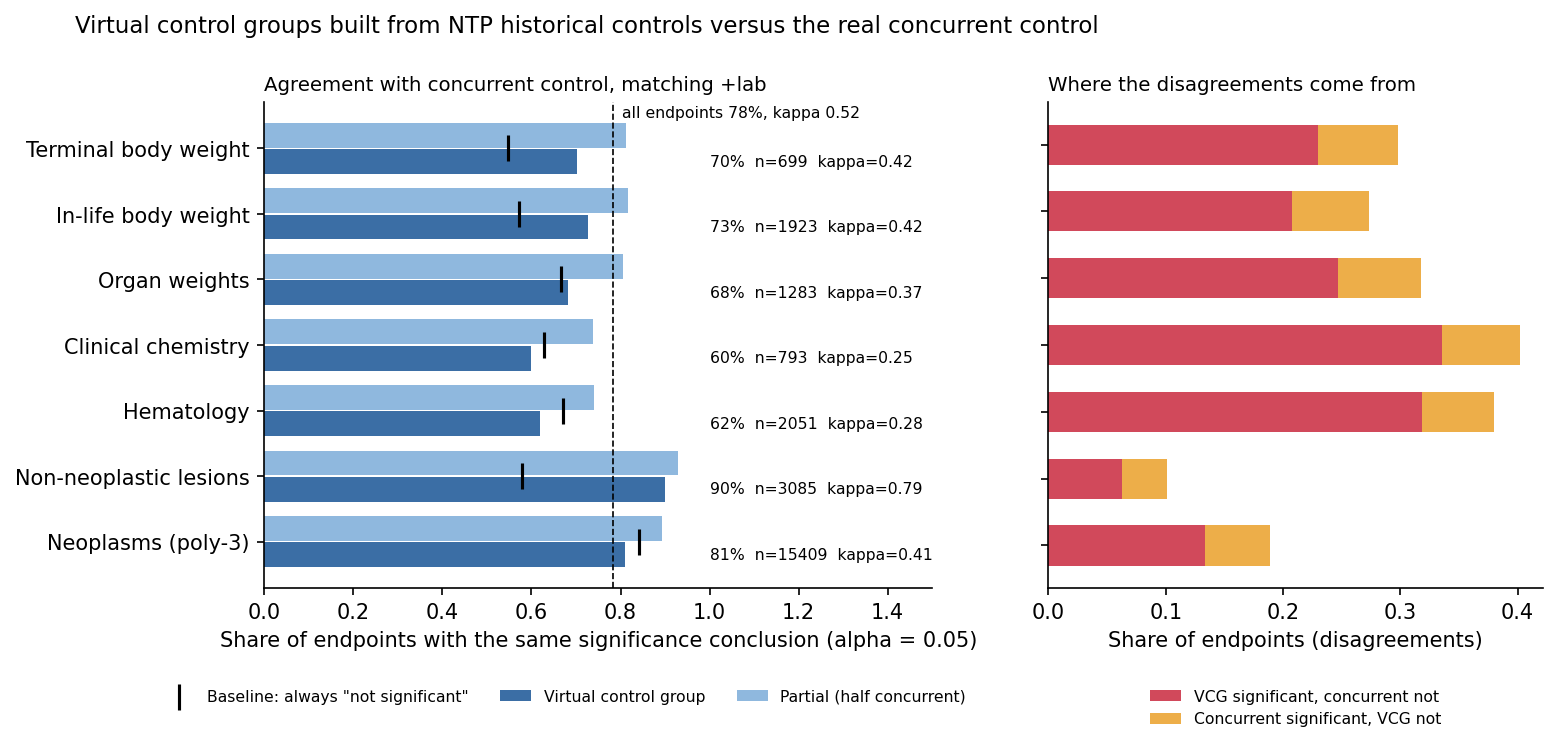

In [11]:
display(Image(filename=str(C.FIGURES_DIR / "headline_agreement.png"), width=1000))

In [12]:
lvl = summary["headline_level"]
t = pd.read_csv(C.TABLES_DIR / "agreement_by_domain_level.csv")
cols = ["domain", "n_endpoints", "agreement", "false_positive", "false_negative", "fp_given_conc_nonsig", "fn_given_conc_sig", "conc_sig_rate", "vcg_sig_rate"]
t[(t["mode"] == "vcg") & (t["level"] == lvl)][cols].set_index("domain").round(3)

,n_endpoints,agreement,false_positive,false_negative,fp_given_conc_nonsig,fn_given_conc_sig,conc_sig_rate,vcg_sig_rate
domain,,,,,,,,
organ_weight,1283,0.683,0.246,0.071,0.370,0.212,0.334,0.509
terminal_bw,699,0.702,0.230,0.068,0.420,0.149,0.452,0.615
inlife_bw,1923,0.726,0.208,0.066,0.486,0.115,0.572,0.714
nonneoplastic lesion,3085,0.899,0.063,0.038,0.149,0.066,0.579,0.604
neoplasm,15409,0.811,0.134,0.055,0.159,0.349,0.159,0.237
clin_chem,793,0.598,0.336,0.066,0.534,0.177,0.371,0.641
hematology,2051,0.620,0.318,0.062,0.476,0.187,0.330,0.587


### Matching strictness and coverage

Each level adds one criterion. Stricter matching should make the pool more
similar to the concurrent group, but it also shrinks the pool: coverage is the
share of study/sex/endpoint units for which a pool of at least twice the control
group size exists.

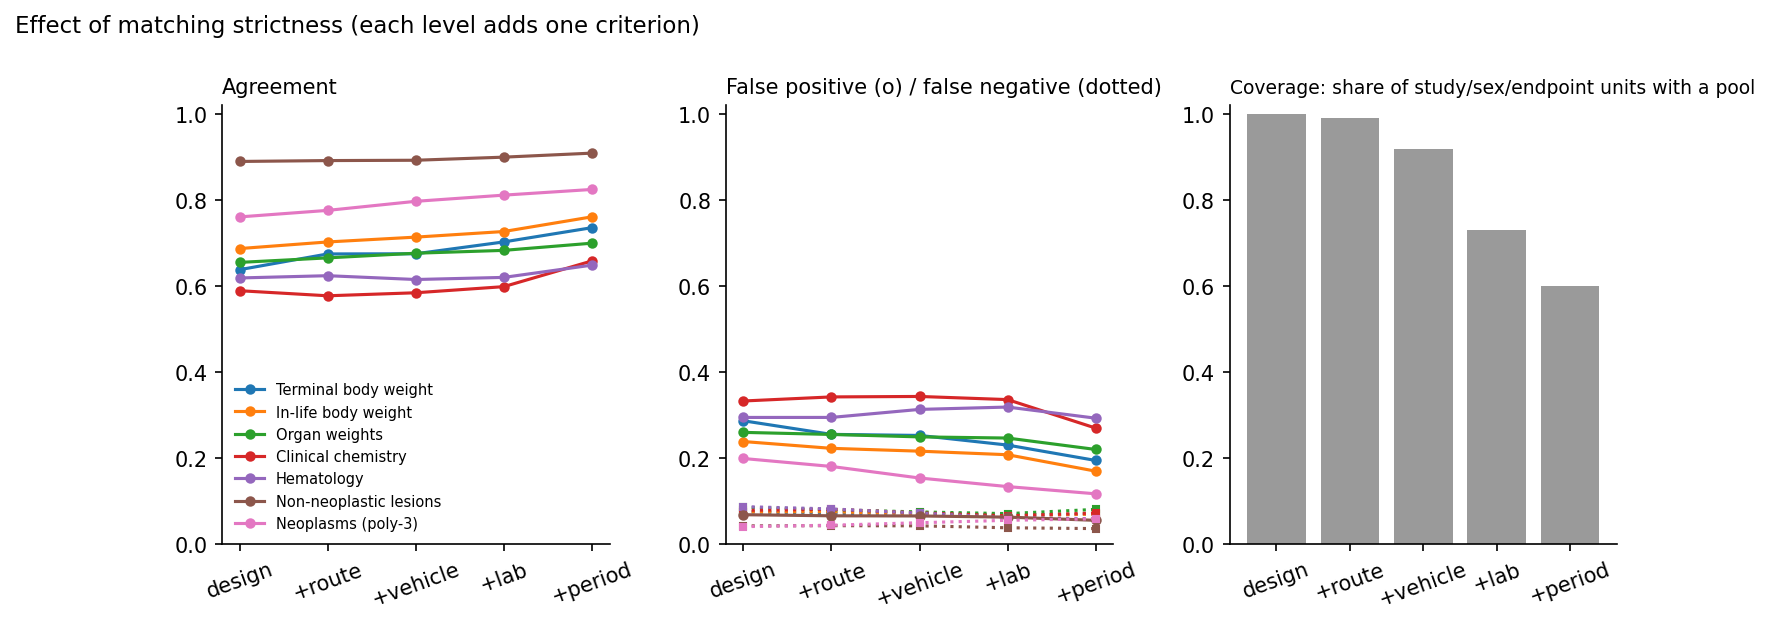

,mode,level,n_endpoints,agreement,false_positive,false_negative,conc_sig_rate,vcg_sig_rate,kappa,trivial_agreement,fp_given_conc_nonsig,fn_given_conc_sig,sensitivity,specificity
0,vcg,L0 design,34570,0.739,0.208,0.053,0.284,0.439,0.448,0.716,0.291,0.187,0.813,0.709
1,vcg,L1 +route,34247,0.751,0.195,0.054,0.285,0.426,0.468,0.715,0.272,0.190,0.810,0.728
2,vcg,L2 +vehicle,31727,0.766,0.178,0.055,0.285,0.408,0.492,0.715,0.249,0.195,0.805,0.751
3,vcg,L3 +laboratory,25243,0.784,0.160,0.056,0.279,0.384,0.518,0.721,0.223,0.200,0.800,0.777
4,vcg,L4 +period (3y),20755,0.802,0.139,0.059,0.287,0.368,0.554,0.713,0.195,0.204,0.796,0.805
5,partial,L0 design,34570,0.842,0.110,0.048,0.284,0.346,0.635,0.716,0.154,0.169,0.831,0.846
6,partial,L1 +route,34297,0.849,0.102,0.049,0.285,0.338,0.649,0.715,0.143,0.171,0.829,0.857
7,partial,L2 +vehicle,33354,0.855,0.096,0.049,0.285,0.331,0.661,0.715,0.134,0.173,0.827,0.866
8,partial,L3 +laboratory,29907,0.865,0.088,0.047,0.284,0.324,0.682,0.716,0.122,0.167,0.833,0.878
9,partial,L4 +period (3y),27263,0.875,0.078,0.047,0.290,0.321,0.706,0.710,0.110,0.163,0.837,0.890


In [13]:
display(Image(filename=str(C.FIGURES_DIR / "agreement_vs_strictness.png"), width=1000))
pd.read_csv(C.TABLES_DIR / "agreement_by_level.csv").round(3)

In [14]:
pd.read_csv(C.TABLES_DIR / "coverage_by_level.csv").round(3)

,level,n_units,coverage
0,L0 design,34570,1.000
1,L1 +route,34247,0.991
2,L2 +vehicle,31727,0.918
3,L3 +laboratory,25243,0.730
4,L4 +period (3y),20755,0.600


### Partial virtual control groups

Half of the concurrent control animals are kept and the other half is replaced
by historical animals.

In [15]:
t = pd.read_csv(C.TABLES_DIR / "agreement_by_level.csv")
t.pivot(index="level", columns="mode", values=["agreement", "false_positive", "false_negative"]).round(3)

agreement        false_positive        false_negative       
mode              partial    vcg        partial    vcg        partial    vcg
level                                                                       
L0 design           0.842  0.739          0.110  0.208          0.048  0.053
L1 +route           0.849  0.751          0.102  0.195          0.049  0.054
L2 +vehicle         0.855  0.766          0.096  0.178          0.049  0.055
L3 +laboratory      0.865  0.784          0.088  0.160          0.047  0.056
L4 +period (3y)     0.875  0.802          0.078  0.139          0.047  0.059

### Drift: time between historical and current study

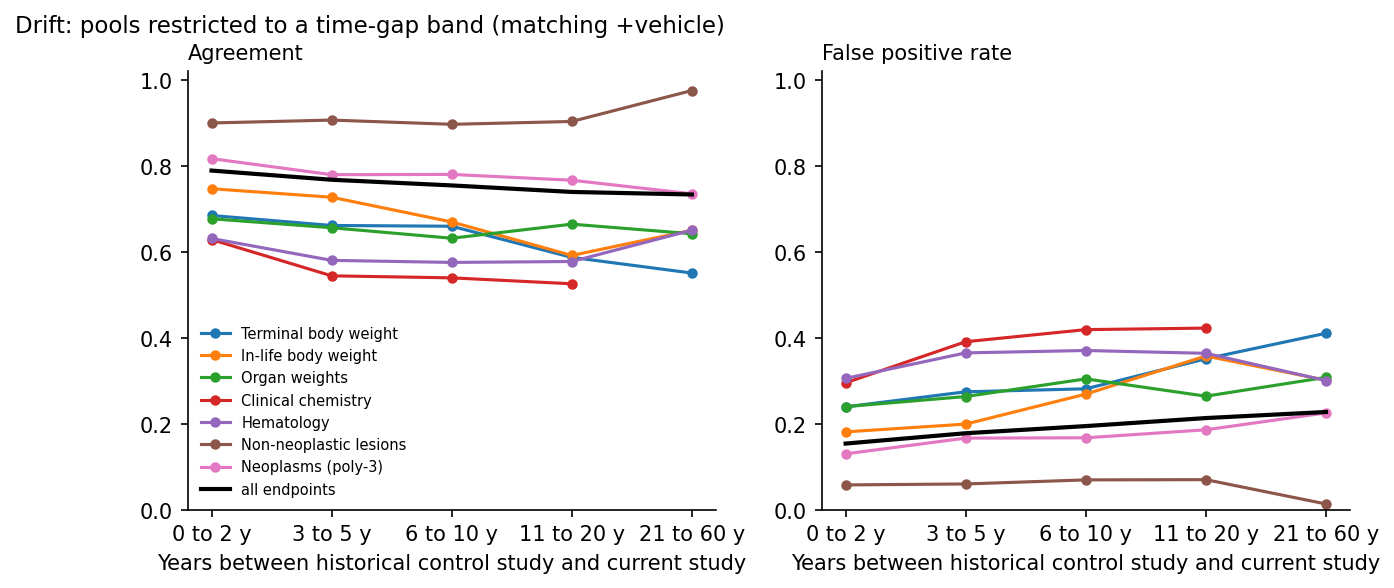

,mode,level,band,n_endpoints,agreement,false_positive,false_negative,conc_sig_rate,vcg_sig_rate,kappa,trivial_agreement,fp_given_conc_nonsig,fn_given_conc_sig,sensitivity,specificity
0,vcg,L2 +vehicle,0-2,25423,0.789,0.155,0.056,0.286,0.384,0.531,0.714,0.216,0.198,0.802,0.784
1,vcg,L2 +vehicle,6-10,16796,0.754,0.195,0.050,0.294,0.438,0.483,0.706,0.276,0.171,0.829,0.724
2,vcg,L2 +vehicle,3-5,18196,0.768,0.179,0.054,0.287,0.412,0.498,0.713,0.250,0.187,0.813,0.750
3,vcg,L2 +vehicle,21-60,7825,0.733,0.228,0.039,0.214,0.403,0.401,0.786,0.290,0.180,0.820,0.710
4,vcg,L2 +vehicle,11-20,14814,0.739,0.214,0.047,0.271,0.438,0.447,0.729,0.293,0.173,0.827,0.707


In [16]:
display(Image(filename=str(C.FIGURES_DIR / "agreement_vs_time_gap.png"), width=900))
pd.read_csv(C.TABLES_DIR / "agreement_by_drift.csv").query("mode == 'vcg'").round(3)

### Which endpoints are suitable?

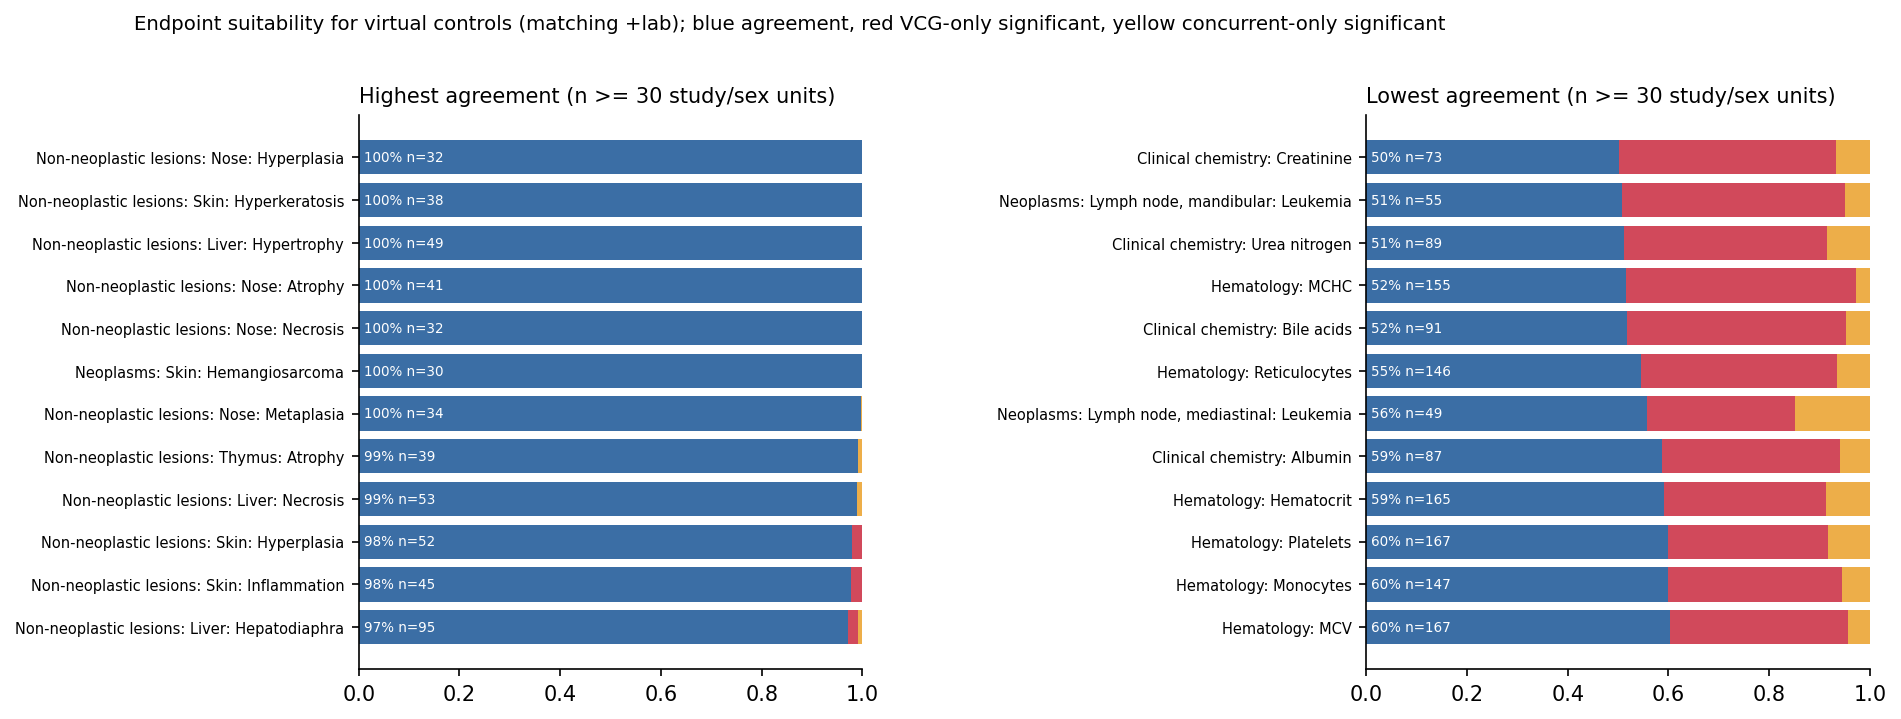

,domain,endpoint,n_endpoints,agreement,false_positive,false_negative
959,clin_chem,Creatinine,73,0.501,0.432,0.067
1709,neoplasm,"Lymph node, mandibular: Leukemia",55,0.507,0.443,0.050
965,clin_chem,Urea nitrogen,89,0.511,0.404,0.085
1014,hematology,MCHC,155,0.516,0.457,0.027
955,clin_chem,Bile acids,91,0.518,0.436,0.047
1342,hematology,Reticulocytes,146,0.545,0.389,0.066
1098,neoplasm,"Lymph node, mediastinal: Leukemia",49,0.558,0.293,0.149
951,clin_chem,Albumin,87,0.588,0.353,0.059
1665,nonneoplastic lesion,Thymus: Atrophy,39,0.991,0.000,0.009
1392,nonneoplastic lesion,Nose: Metaplasia,34,0.997,0.000,0.003


In [17]:
display(Image(filename=str(C.FIGURES_DIR / "endpoint_suitability.png"), width=1000))
t = pd.read_csv(C.TABLES_DIR / "agreement_by_endpoint.csv")
t = t[(t["level"] == lvl) & (t["n_endpoints"] >= 30)].sort_values("agreement")
pd.concat([t.head(8), t.tail(8)])[["domain", "endpoint", "n_endpoints", "agreement", "false_positive", "false_negative"]].round(3)

### Does the concurrent control itself look like the virtual one?

For continuous endpoints we also tested the concurrent control group against each
drawn VCG (Welch t-test). The share of significant differences is a direct
measure of how often the historical pool does not represent the current
control group, independent of any treatment effect.

In [18]:
pd.read_csv(C.TABLES_DIR / "control_vs_vcg.csv").pivot(index="domain", columns="level", values="share_concurrent_differs_from_vcg").round(3)

level,L0 design,L1 +route,L2 +vehicle,L3 +laboratory,L4 +period (3y)
domain,,,,,
clin_chem,0.383,0.394,0.421,0.407,0.328
hematology,0.319,0.322,0.350,0.344,0.340
inlife_bw,0.447,0.417,0.401,0.348,0.265
organ_weight,0.277,0.264,0.270,0.252,0.214
terminal_bw,0.405,0.361,0.346,0.285,0.210


## 5. The three pre-specified improvements

`docs/analysis_plan.md` fixed the split, the settings and the rule for calling a
change helpful before any of it was run. Targets that started before 1990 are the
development set; the rest is held out.

First the mechanism the improvements are aimed at: how much of the variance in a
control group sits *between* studies rather than within one.

In [19]:
v = pd.read_csv(C.TABLES_DIR / "between_study_variance.csv")
by_domain = pd.read_csv(C.TABLES_DIR / "between_study_variance_by_domain.csv")
print(f"{len(v)} stratum x endpoint combinations with at least 3 historical control groups")
by_domain.round(3)

1180 stratum x endpoint combinations with at least 3 historical control groups


,domain,strata_endpoints,median_icc,q25_icc,q75_icc,implied_fp_individual,implied_fp_whole_group
0,clin_chem,141,0.422,0.206,0.639,0.288,0.475
1,hematology,379,0.426,0.160,0.715,0.290,0.479
2,inlife_bw,308,0.223,0.099,0.371,0.179,0.300
3,organ_weight,232,0.253,0.087,0.442,0.196,0.330
4,terminal_bw,120,0.197,0.063,0.365,0.164,0.274


In [20]:
# the most and least study-dependent endpoints
icc = v.groupby(["domain", "endpoint"])["icc"].median().sort_values()
pd.concat([icc.head(5), icc.tail(5)]).round(3)

domain        endpoint             
hematology    Eosinophils              0.064
organ_weight  Testis weight, right     0.074
              Thymus weight            0.133
inlife_bw     Body weight, week 104    0.134
hematology    Neutrophils              0.170
clin_chem     ALP                      0.652
              Urea nitrogen            0.678
hematology    MCHC                     0.723
              MCV                      0.835
              Reticulocytes            0.887
Name: icc, dtype: float64

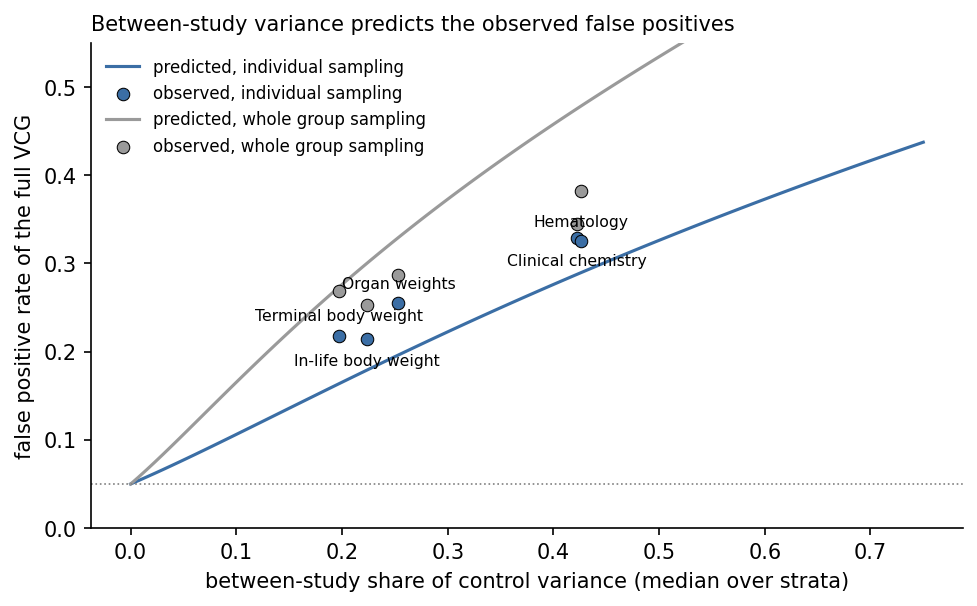

In [21]:
# observed false positives of each sampling scheme, held-out set
md_ = pd.read_csv(C.TABLES_DIR / "methods_by_domain.csv")
obs = (md_[(md_["set"] == "holdout") & (md_["mode"] == "vcg") & md_["method"].isin(["baseline", "whole_group"])]
       .pivot(index="domain", columns="method", values="false_positive"))
obs = obs.join(by_domain.set_index("domain")["median_icc"], how="inner").dropna().sort_values("median_icc")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
share = np.linspace(0, 0.75, 100)
for sampling, color in [("individual", "#3b6ea5"), ("whole_group", "#9a9a9a")]:
    ax.plot(share, MM.implied_false_positive_rate(share, n=10, sampling=sampling), color=color,
            label=f"predicted, {sampling.replace('_', ' ')} sampling")
    col = "baseline" if sampling == "individual" else "whole_group"
    ax.scatter(obs["median_icc"], obs[col], color=color, zorder=3, edgecolor="k", linewidth=0.5,
               label=f"observed, {sampling.replace('_', ' ')} sampling")
for i, (dom, r) in enumerate(obs.iterrows()):
    ax.annotate(DOM.get(dom, dom), (r["median_icc"], r["baseline"]), fontsize=7.5,
                xytext=(0, -13 if i % 2 else 7), textcoords="offset points", ha="center")
ax.axhline(0.05, color="grey", lw=0.8, ls=":")
ax.set_ylim(0, 0.55)
ax.set_xlabel("between-study share of control variance (median over strata)")
ax.set_ylabel("false positive rate of the full VCG")
ax.set_title("Between-study variance predicts the observed false positives", loc="left", fontsize=10)
ax.legend(fontsize=8, frameon=False, loc="upper left")
plt.show()

### Did the three changes help?

The paired table compares each method with the current one on exactly the
endpoints both can serve, with a bootstrap over studies.

In [22]:
vs = pd.read_csv(C.TABLES_DIR / "methods_vs_baseline.csv")
cols = ["method", "mode", "domain", "n_paired", "kappa_baseline", "kappa_method", "kappa_diff",
        "ci_low", "ci_high", "verdict"]
vs[(vs["set"] == "holdout") & (vs["domain"] == "all")][cols].round(3)

,method,mode,domain,n_paired,kappa_baseline,kappa_method,kappa_diff,ci_low,ci_high,verdict
23,bw_matched,partial,all,17802,0.693,0.702,0.009,0.004,0.014,no clear difference
31,bw_matched,vcg,all,12863,0.558,0.567,0.009,0.004,0.015,no clear difference
43,bw_ancova,partial,all,3070,0.631,0.642,0.011,-0.008,0.028,no clear difference
47,bw_ancova,vcg,all,2114,0.437,0.483,0.046,0.022,0.071,no clear difference
71,whole_group,partial,all,14062,0.702,0.597,-0.105,-0.115,-0.095,hurt
79,whole_group,vcg,all,14046,0.548,0.517,-0.031,-0.038,-0.024,hurt
97,hierarchical,partial,all,4093,0.582,0.769,0.186,0.161,0.212,helped
103,hierarchical,vcg,all,4091,0.379,0.390,0.011,-0.031,0.050,no clear difference
109,tarone,partial,all,7506,0.706,0.498,-0.208,-0.250,-0.177,hurt
111,tarone,vcg,all,7506,0.530,0.442,-0.089,-0.127,-0.054,hurt


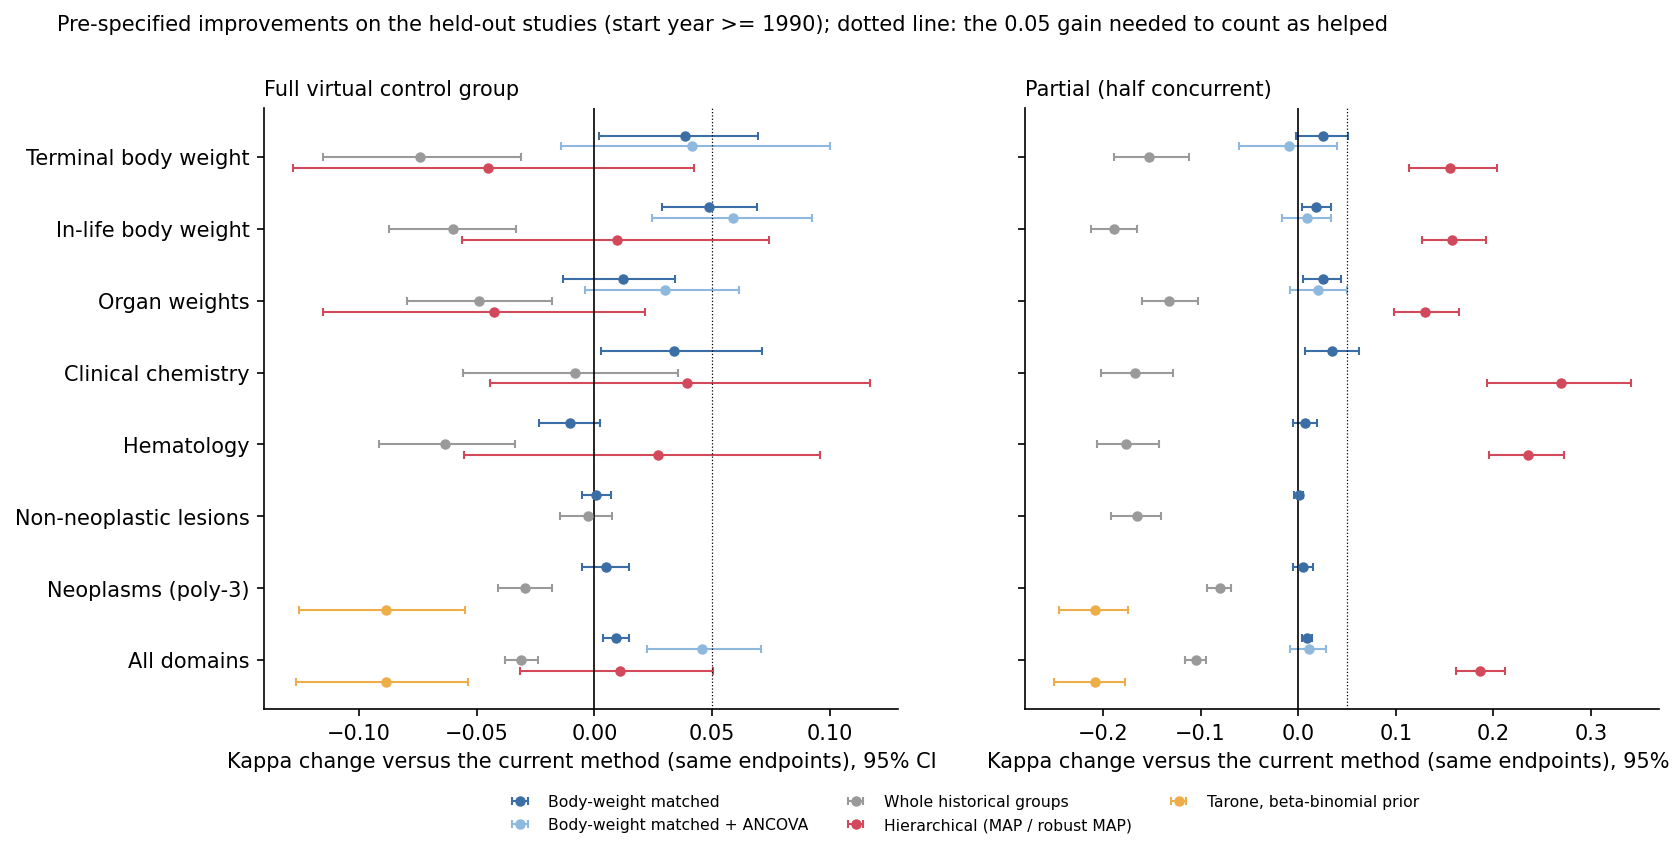

In [23]:
display(Image(filename=str(C.FIGURES_DIR / "methods_comparison.png"), width=1000))

In [24]:
# the verdicts agree between the development and the held-out set
vs[vs["domain"] == "all"].pivot_table(index=["method", "mode"], columns="set",
                                      values="kappa_diff").round(3)

set                   development  holdout
method       mode                         
bw_ancova    partial       -0.008    0.011
             vcg           -0.007    0.046
bw_matched   partial        0.010    0.009
             vcg            0.009    0.009
hierarchical partial        0.186    0.186
             vcg           -0.010    0.011
tarone       partial       -0.219   -0.208
             vcg           -0.106   -0.089
whole_group  partial       -0.090   -0.105
             vcg           -0.030   -0.031

### Post-hoc: was the partial gain really borrowing?

The hierarchical partial VCG was the one large pre-specified gain. A partial
design changes two things at once, so the same design was also analysed using
only the kept half of the concurrent controls, with no virtual animals. This was
not in the plan and is recorded as a deviation.

In [25]:
ph = pd.read_csv(C.TABLES_DIR / "posthoc_half_concurrent.csv")
ph[(ph["set"] == "holdout") & (ph["domain"] == "all")][
    ["method", "comparator", "n_paired", "kappa_baseline", "kappa_method", "kappa_diff",
     "ci_low", "ci_high", "verdict"]].round(3)

,method,comparator,n_paired,kappa_baseline,kappa_method,kappa_diff,ci_low,ci_high,verdict
15,half_concurrent,baseline,18958,0.682,0.773,0.091,0.076,0.106,helped
27,hierarchical,half_concurrent,4093,0.786,0.769,-0.018,-0.034,-0.003,hurt
31,half_concurrent_trend,baseline_trend,9418,0.699,0.660,-0.040,-0.068,-0.013,hurt
35,tarone,half_concurrent_trend,7506,0.667,0.498,-0.169,-0.208,-0.130,hurt


In [26]:
m = pd.read_csv(C.TABLES_DIR / "methods_overall.csv")
m[m["set"] == "holdout"].sort_values(["mode", "kappa"], ascending=[True, False])[
    ["method", "mode", "n_units", "agreement", "trivial_agreement", "kappa",
     "sensitivity", "specificity", "false_positive"]].round(3)

,method,mode,n_units,agreement,trivial_agreement,kappa,sensitivity,specificity,false_positive
24,half_concurrent,partial,18958,0.904,0.695,0.773,0.838,0.933,0.047
9,hierarchical,partial,4093,0.888,0.583,0.769,0.846,0.918,0.048
3,bw_matched,partial,17802,0.869,0.693,0.702,0.839,0.883,0.081
1,baseline,partial,18958,0.860,0.695,0.682,0.838,0.870,0.090
27,half_concurrent_trend,partial,9418,0.953,0.917,0.660,0.620,0.983,0.016
5,bw_ancova,partial,3070,0.821,0.509,0.642,0.857,0.784,0.106
7,whole_group,partial,14062,0.815,0.698,0.597,0.851,0.799,0.140
17,tarone,partial,7506,0.901,0.915,0.498,0.715,0.918,0.075
2,bw_matched,vcg,12863,0.803,0.698,0.567,0.811,0.800,0.140
0,baseline,vcg,15953,0.784,0.700,0.532,0.815,0.770,0.161


Reading those three tables together: halving the concurrent control group and
analysing it on its own (`half_concurrent`) agrees with the full concurrent
control better than any virtual control group does, and the robust MAP prior does
not improve on it. The borrowing is not what produced the gain. The exception is
the trend test on neoplasms, where losing half the controls does cost power.

## 6. Reading the results

* Agreement is high for endpoints with little between-study variation and low for
  endpoints that drift between laboratories and decades.
* Disagreements are mostly *extra* significant findings with the VCG, which is
  what the between-study variance predicts quantitatively.
* Of the three pre-specified improvements, body-weight matching helped a little,
  whole-group sampling and Tarone's test hurt, and hierarchical borrowing helped
  only in a sense the post-hoc control takes back.
* All of this is a retrospective comparison on public NTP data with the matching
  attributes available in CEBS. It is not a regulatory validation. See the README
  for the limitations.